# Chapitre 8 - Cours 2 : délais non bornés et détection des pannes

Le cours 1 a montré que le délai d'expiration est le seul moyen général de détecter une
panne. Reste à le choisir. Ce notebook explique **d'où vient la variabilité** des délais
réseau (les files d'attente), comment **régler** un délai (fixe ou adaptatif, jusqu'au
détecteur « phi accrual ») et **pourquoi** nos réseaux ne garantissent aucun délai
maximal alors que le téléphone le faisait. Il couvre les sections *Timeouts and
Unbounded Delays* (*Network congestion and queueing*, encadré *TCP Versus UDP*)
et *Synchronous Versus Asynchronous Networks* (*Can we not simply make network delays predictable?*, encadré *Latency and Resource Utilization*).

**Plan.**

1. Choisir un délai d'expiration : un compromis sans bonne réponse.
2. Congestion et files d'attente : d'où viennent les délais.
3. Des délais adaptatifs : estimateur de TCP et détecteur phi accrual.
4. Réseaux synchrones contre réseaux asynchrones.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Choisir un délai d'expiration (section *Timeouts and Unbounded Delays*)

**Le monde idéal.** Imaginons un réseau qui livre tout paquet en moins de $d$ (ou le
perd), et des serveurs qui traitent toute requête en moins de $r$. Alors toute requête
réussie reçoit sa réponse en moins de $2d + r$, et ne rien recevoir dans ce délai prouve
une panne : $2d + r$ serait le délai d'expiration parfait.

**Le monde réel.** Les réseaux asynchrones ont des délais **non bornés** (ils livrent
aussi vite que possible, sans maximum garanti) et les serveurs ne garantissent pas de
temps de traitement maximal. Pour la détection de pannes, être rapide **la plupart du
temps** ne suffit pas : avec un délai court, un pic passager suffit à déstabiliser le
système. Regardons la distribution synthétique d'un million d'allers-retours dans un
centre de données (`ds.rtt_samples` : corps log-normal de médiane 0,5 ms et rares
surcoûts de queue lourde).

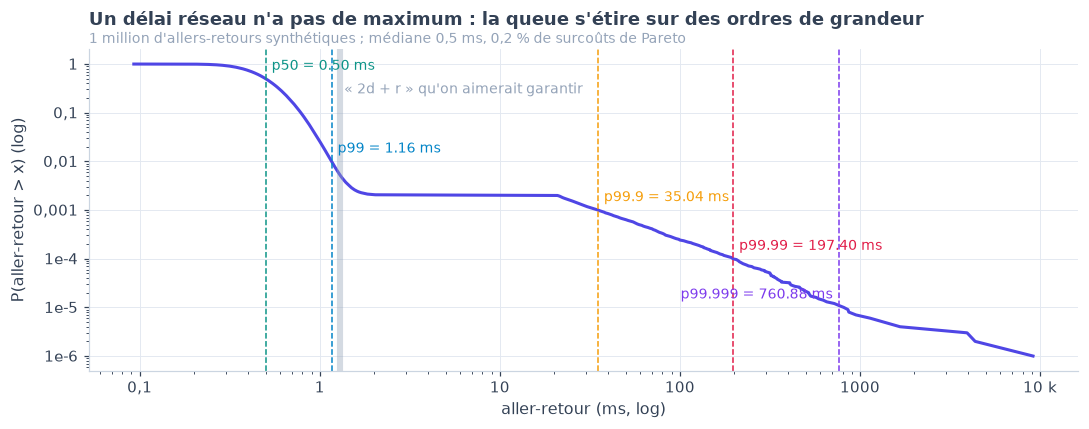

p50          0.50
p99          1.16
p99.9       35.04
p99.99     197.40
p99.999    760.88
Name: aller-retour (ms), dtype: float64

In [2]:
rtt = ds.rtt_samples(1_000_000, seed=1)
qs = [50, 99, 99.9, 99.99, 99.999]
vals = np.percentile(rtt, qs)
x = np.sort(rtt)
idx = np.unique(np.r_[np.arange(0, x.size, 500), x.size - np.geomspace(1, x.size // 2, 400).astype(int)])
ccdf = 1 - idx / x.size
fig, ax = plt.subplots(figsize=(10, 4))
ax.loglog(x[idx], ccdf, color=INDIGO)
for q, v, c in zip(qs, vals, [TEAL, SKY, AMBER, ROSE, VIOLET]):
    ax.axvline(v, color=c, ls="--", lw=1)
    last = q == qs[-1]
    ax.text(v / 1.08 if last else v * 1.08, (1 - q / 100) * 1.3, f"p{q:g} = {v:.2f} ms", color=c, fontsize=9,
            va="bottom", ha="right" if last else "left")
ax.axvline(1.3, color=GRAY, lw=4, alpha=0.4)
ax.text(1.3 * 1.05, 0.25, "« 2d + r » qu'on aimerait garantir", color=GRAY, fontsize=9)
plain_log_axis(ax)
ax.set_xlabel("aller-retour (ms, log)"); ax.set_ylabel("P(aller-retour > x) (log)")
ax.set_title("Un délai réseau n'a pas de maximum : la queue s'étire sur des ordres de grandeur")
subtitle(ax, "1 million d'allers-retours synthétiques ; médiane 0,5 ms, 0,2 % de surcoûts de Pareto")
plt.tight_layout(); plt.show()
pd.Series(vals, index=[f"p{q:g}" for q in qs], name="aller-retour (ms)").round(2)

La médiane vaut une demi-milliseconde, mais un aller-retour sur mille dépasse 35 ms et
un sur dix mille près de 200 ms : quelle que soit la valeur choisie, **certains**
messages arriveront après. Le choix du délai est donc un **compromis** :

- délai **long** : on attend longtemps avant de déclarer un nœud mort (pendant ce temps,
  les utilisateurs patientent ou voient des erreurs) ;
- délai **court** : on détecte vite, mais on déclare morts des nœuds simplement ralentis
  (pic de charge du nœud ou du réseau).

Quantifions-le avec un détecteur par **battements de cœur** : le nœud surveillé émet un
battement toutes les 100 ms ; le détecteur le soupçonne s'il n'a rien reçu depuis $T$.
On mesure le nombre de **fausses suspicions** par jour (pour un nœud vivant) et le
**délai de détection** moyen d'une vraie panne, pour deux réseaux : calme, et partagé
avec un « voisin bruyant ».

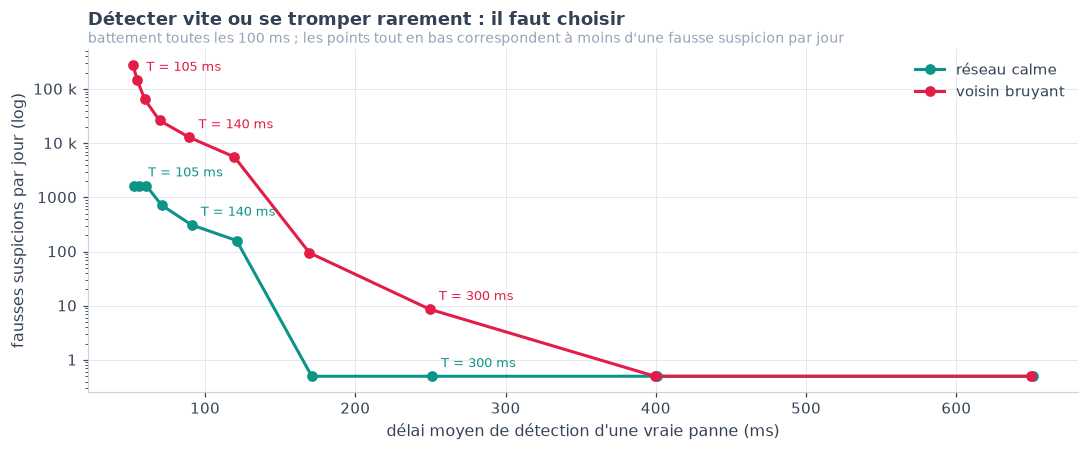

In [3]:
n_hb = 200_000
reseaux = {
    "réseau calme": ds.rtt_samples(n_hb, seed=1, median_ms=1.0, sigma=0.3, spike_prob=0.002, spike_scale_ms=20) / 2,
    "voisin bruyant": ds.rtt_samples(n_hb, seed=2, median_ms=8.0, sigma=0.8, spike_prob=0.02, spike_scale_ms=60) / 2,
}
timeouts = [102, 105, 110, 120, 140, 170, 220, 300, 450, 700]
rows = []
for nom, delays in reseaux.items():
    arr = ds.heartbeat_arrivals(n_hb, 100.0, delays)
    for T in timeouts:
        r = ds.fixed_timeout_eval(arr, T, 100.0)
        rows.append(dict(reseau=nom, T=T, fp_jour=r["faux_positifs"] * 864_000, detection=r["detection_moy"]))
TT = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.2))
for (nom, g), c in zip(TT.groupby("reseau", sort=False), [TEAL, ROSE]):
    ax.plot(g.detection, g.fp_jour.clip(lower=0.5), "o-", color=c, label=nom)
    for _, row in g.iterrows():
        if row["T"] in (105, 140, 300):
            ax.annotate(f"T = {row['T']:g} ms", (row.detection, max(row.fp_jour, 0.5)), textcoords="offset points",
                        xytext=(6, 6), fontsize=8.5, color=c)
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("délai moyen de détection d'une vraie panne (ms)")
ax.set_ylabel("fausses suspicions par jour (log)")
ax.set_title("Détecter vite ou se tromper rarement : il faut choisir")
subtitle(ax, "battement toutes les 100 ms ; les points tout en bas correspondent à moins d'une fausse suspicion par jour")
ax.legend()
plt.tight_layout(); plt.show()

Chaque courbe est une **frontière** : on ne peut pas à la fois détecter en 10 ms et ne
jamais se tromper. Surtout, la bonne valeur dépend du réseau : un délai de 140 ms, très
sûr sur le réseau calme, produit des milliers de fausses suspicions par jour avec le
voisin bruyant.

**Déclarer mort trop tôt coûte cher.** Si le nœud était vivant et au milieu d'une action
(envoyer un courriel), un autre nœud la reprend et elle est faite **deux fois**. Et les
responsabilités du nœud « mort » sont transférées aux autres, ce qui ajoute de la charge
au pire moment. Si le nœud n'était que **surchargé**, on obtient une **défaillance en
cascade**. Modélisons dix nœuds de capacités légèrement différentes (100 requêtes/s à
±15 %) qui se partagent une charge occupant 75 % de la capacité totale ; le contrôle de
santé déclare mort un nœud dont le temps de réponse moyen (file M/M/1 :
$R = 1/(\mu - \lambda)$) dépasse $T$. Au départ, **un seul** nœud tombe vraiment.

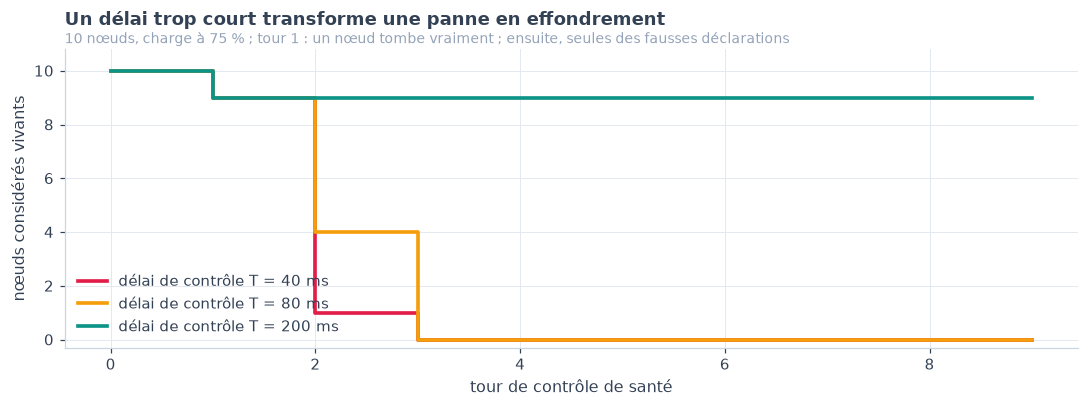

In [4]:
def cascade(T_ms, n=10, charge=0.75, rounds=8, seed=3):
    r = np.random.default_rng(seed)
    mu = 100 * (1 + 0.15 * r.uniform(-1, 1, n))
    lam_tot = charge * mu.sum()
    alive = np.ones(n, bool)
    alive[np.argmax(mu)] = False                       # la vraie panne : le plus gros nœud
    hist = [n, alive.sum()]
    for _ in range(rounds):
        lam = lam_tot / max(alive.sum(), 1)
        R = np.where(lam < mu, 1 / np.maximum(mu - lam, 1e-9), np.inf) * 1e3
        newly = alive & (R > T_ms)
        alive &= ~newly
        hist.append(alive.sum())
    return hist

fig, ax = plt.subplots(figsize=(10, 3.8))
for T, c in [(40, ROSE), (80, AMBER), (200, TEAL)]:
    h = cascade(T)
    ax.step(range(len(h)), h, where="post", color=c, lw=2.4, label=f"délai de contrôle T = {T} ms")
ax.set_xlabel("tour de contrôle de santé"); ax.set_ylabel("nœuds considérés vivants")
ax.set_ylim(-0.3, 10.8)
ax.set_title("Un délai trop court transforme une panne en effondrement")
subtitle(ax, "10 nœuds, charge à 75 % ; tour 1 : un nœud tombe vraiment ; ensuite, seules des fausses déclarations")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Avec $T = 200$ ms, le système absorbe la panne : les neuf survivants sont plus chargés
mais restent sous le seuil. Avec $T = 80$ ou $40$ ms, les nœuds les plus faibles,
ralentis par la charge supplémentaire, sont déclarés morts à tort ; leur charge
retombe sur les autres, qui ralentissent à leur tour... jusqu'à ce que **plus aucun**
nœud ne soit considéré vivant, alors qu'un seul était réellement en panne (c'est la
situation extrême évoquée par le livre, où tous les nœuds se déclarent morts
mutuellement).

> **À retenir.** Faute de délai maximal garanti, aucun délai d'expiration n'est
> « correct » : c'est un compromis entre délai de détection et fausses suspicions, qui
> dépend du réseau. Une fausse déclaration de décès peut dupliquer une action et, sous
> forte charge, déclencher une cascade.

## 2. Congestion et files d'attente (section *Network congestion and queueing*)

Comme les temps de trajet en voiture, les délais des paquets varient surtout à cause des
**embouteillages**, c'est-à-dire des **files d'attente** :

- plusieurs machines envoient en même temps vers la même destination : le commutateur
  met les paquets en file et les émet un par un sur le lien de sortie (congestion) ; si
  la file déborde, le paquet est **perdu** et devra être renvoyé, alors que le réseau
  fonctionne parfaitement ;
- à l'arrivée, si tous les cœurs sont occupés, le système d'exploitation met la requête
  en file jusqu'à ce que l'application la prenne ;
- en environnement virtualisé, une machine virtuelle est régulièrement **mise en pause**
  quelques dizaines de millisecondes pendant qu'une autre utilise le cœur ; ses paquets
  attendent dans un tampon de l'hyperviseur ;
- TCP limite son débit pour ne pas surcharger le réseau : les données attendent chez
  l'émetteur avant même d'entrer dans le réseau.

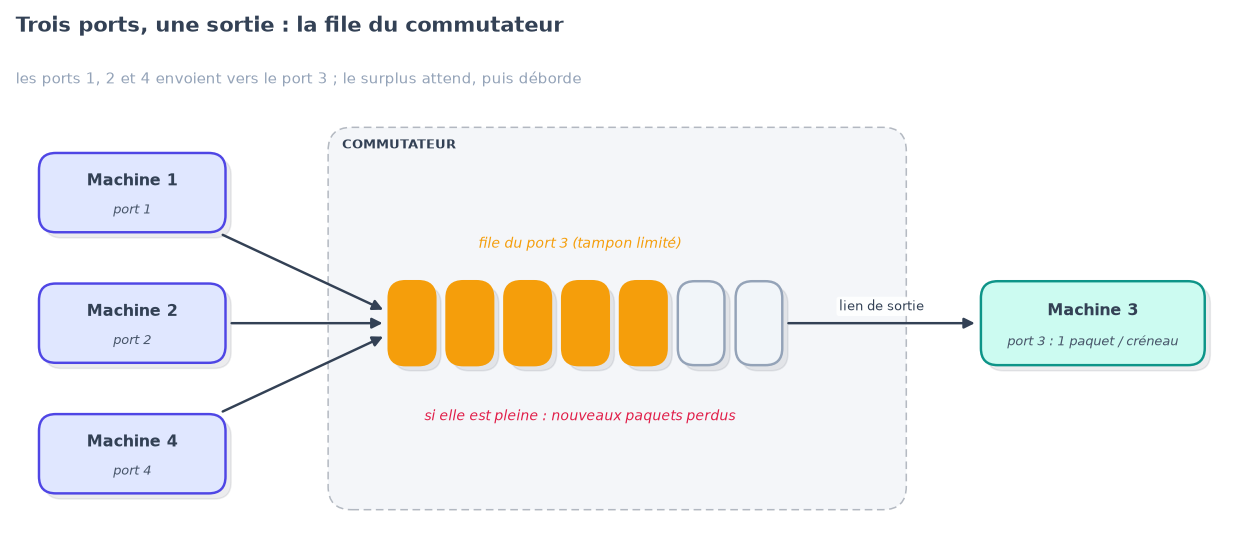

In [5]:
d = Diagram(13, 4.8, title="Trois ports, une sortie : la file du commutateur",
            subtitle="les ports 1, 2 et 4 envoient vers le port 3 ; le surplus attend, puis déborde")
for k, (p, y) in enumerate([("1", 3.8), ("2", 2.4), ("4", 1.0)]):
    d.box(f"p{p}", 1.3, y, f"Machine {p}", sub=f"port {p}", color=INDIGO, w=2.0, h=0.85)
d.group(3.4, 0.4, 9.6, 4.5, "commutateur", color=SLATE)
for k in range(7):
    d.box(f"q{k}", 4.3 + k * 0.62, 2.4, "", color=AMBER if k < 5 else GRAY, w=0.5, h=0.9, filled=k < 5)
d.note(6.1, 3.25, "file du port 3 (tampon limité)", color=AMBER)
d.note(6.1, 1.4, "si elle est pleine : nouveaux paquets perdus", color=ROSE)
d.box("p3", 11.6, 2.4, "Machine 3", sub="port 3 : 1 paquet / créneau", color=TEAL, w=2.4, h=0.9)
for p in ("p1", "p2", "p4"):
    d.arrow(p, "q0")
d.arrow("q6", "p3", "lien de sortie")
d.show()

Simulons ce port de sortie (`ds.switch_port_sim`) : trois entrées en rafales (sources
on/off, rafales de 8 paquets en moyenne), un lien de sortie qui émet un paquet par
créneau, un tampon de 64 paquets. On fait varier la charge offerte, c'est-à-dire la
fraction de la capacité du lien de sortie demandée en moyenne.

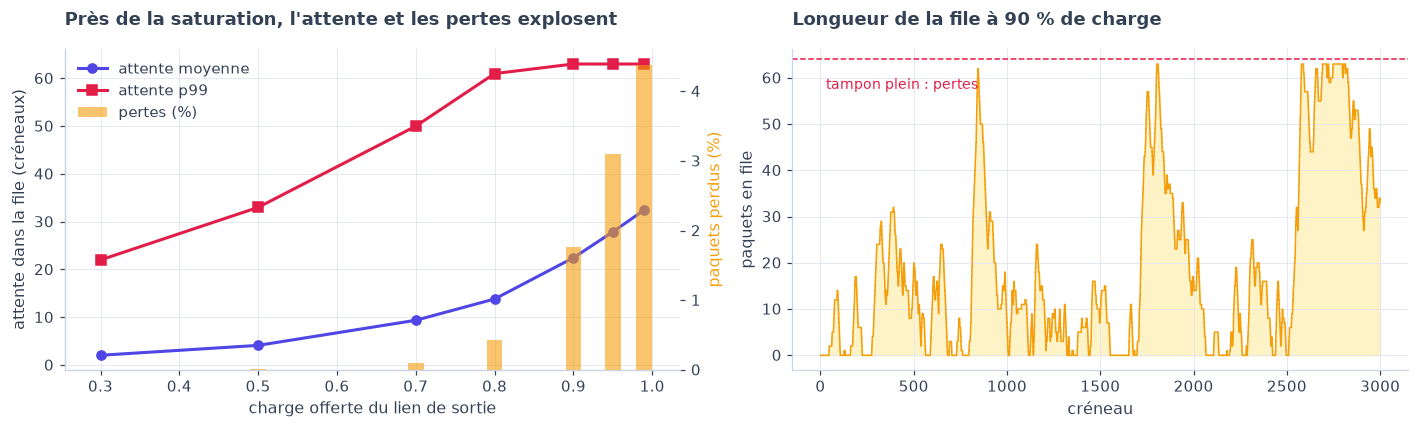

,charge,attente_moy,attente_p99,pertes
0,0.30,2.05,22.0,0.00
1,0.50,4.12,33.0,0.01
2,0.70,9.37,50.0,0.10
3,0.80,13.83,61.0,0.43
4,0.90,22.45,63.0,1.76
5,0.95,27.87,63.0,3.10
6,0.99,32.48,63.0,4.38


In [6]:
loads = [0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
S = []
for L in loads:
    r = ds.switch_port_sim(load=L, buffer=64, slots=150_000, seed=1)
    S.append(dict(charge=L, attente_moy=r["waits"].mean(), attente_p99=np.percentile(r["waits"], 99),
                  pertes=r["drop_rate"] * 100))
S = pd.DataFrame(S)
trace = ds.switch_port_sim(load=0.9, buffer=64, slots=3000, seed=2)["queue"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(S.charge, S.attente_moy, "o-", color=INDIGO, label="attente moyenne")
ax.plot(S.charge, S.attente_p99, "s-", color=ROSE, label="attente p99")
ax.set_xlabel("charge offerte du lien de sortie"); ax.set_ylabel("attente dans la file (créneaux)")
ax2 = ax.twinx(); ax2.bar(S.charge, S.pertes, width=0.02, color=AMBER, alpha=0.6, label="pertes (%)")
ax2.set_ylabel("paquets perdus (%)", color=AMBER); ax2.grid(False)
ax.set_title("Près de la saturation, l'attente et les pertes explosent")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax = axes[1]
ax.fill_between(range(trace.size), trace, color=LIGHT[AMBER], step="post")
ax.step(range(trace.size), trace, color=AMBER, lw=1, where="post")
ax.axhline(64, color=ROSE, ls="--", lw=1); ax.text(30, 60, "tampon plein : pertes", color=ROSE, fontsize=9, va="top")
ax.set_xlabel("créneau"); ax.set_ylabel("paquets en file")
ax.set_title("Longueur de la file à 90 % de charge")
plt.tight_layout(); plt.show()
S.round(2)

À 30 % de charge, un paquet n'attend presque jamais ; à 90 %, il attend en moyenne une
vingtaine de créneaux, le p99 dépasse 60 créneaux et plus d'un paquet sur cent est perdu
**alors qu'aucun équipement n'est en panne**. La file (à droite) alterne longues
périodes calmes et rafales qui la remplissent jusqu'au débordement : c'est la
**variabilité** des délais, d'autant plus forte que le système est proche de sa capacité
(chapitre 1, cours 3).

**La perte se voit comme un délai.** Quand TCP retransmet un paquet perdu, l'application
ne voit pas la perte, mais elle subit l'attente : expiration du délai de retransmission
(au moins 200 ms sous Linux) puis nouvel envoi. Simulons des réponses de 10 paquets sur un
réseau où l'aller-retour vaut 0,5 ms, en faisant varier le taux de perte.

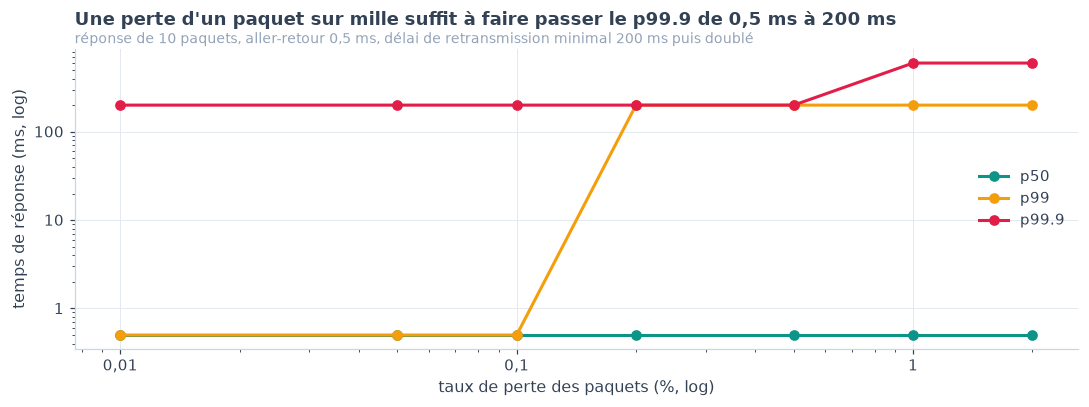

In [7]:
def reponse_tcp(p, n_paquets=10, n=200_000, rtt=0.5, rto=200.0, seed=0):
    r = np.random.default_rng(seed)
    tries = r.geometric(1 - p, size=(n, n_paquets)) - 1          # retransmissions par paquet
    extra = rto * (2.0 ** tries - 1)                               # attente exponentielle 200, 400...
    return rtt + extra.max(axis=1)

pertes = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02]
P = pd.DataFrame([dict(perte=p, **{f"p{q}": np.percentile(reponse_tcp(p), q) for q in (50, 99, 99.9)}) for p in pertes])
fig, ax = plt.subplots(figsize=(10, 3.8))
for q, c in [("p50", TEAL), ("p99", AMBER), ("p99.9", ROSE)]:
    ax.plot(P.perte * 100, P[q], "o-", color=c, label=q)
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax)
ax.set_xlabel("taux de perte des paquets (%, log)"); ax.set_ylabel("temps de réponse (ms, log)")
ax.set_title("Une perte d'un paquet sur mille suffit à faire passer le p99.9 de 0,5 ms à 200 ms")
subtitle(ax, "réponse de 10 paquets, aller-retour 0,5 ms, délai de retransmission minimal 200 ms puis doublé")
ax.legend()
plt.tight_layout(); plt.show()

Dès que la probabilité qu'**un** des 10 paquets soit perdu dépasse 1 %, le p99 bondit de
0,5 ms à environ 200 ms : un facteur 400 dû à quelques pertes de congestion.

### TCP ou UDP ? (encadré *TCP Versus UDP*)

Les applications sensibles à la latence (visioconférence, voix sur IP) utilisent souvent
**UDP** : sans contrôle de flux ni retransmission, il évite une partie de la variabilité
(pas celle des files des commutateurs ni de l'ordonnancement). C'est un bon choix quand
une donnée en retard **ne vaut plus rien** : un paquet de voix doit être joué à une
échéance précise ; s'il manque, l'application joue un bref silence et continue. La
relance a lieu « au niveau humain » (« pardon, tu peux répéter ? »). Mesurons-le avec un
flux audio régulier (une petite trame par unité de temps) qui partage une file avec du
trafic en rafales : quelle part des trames arrive après l'échéance de lecture ?

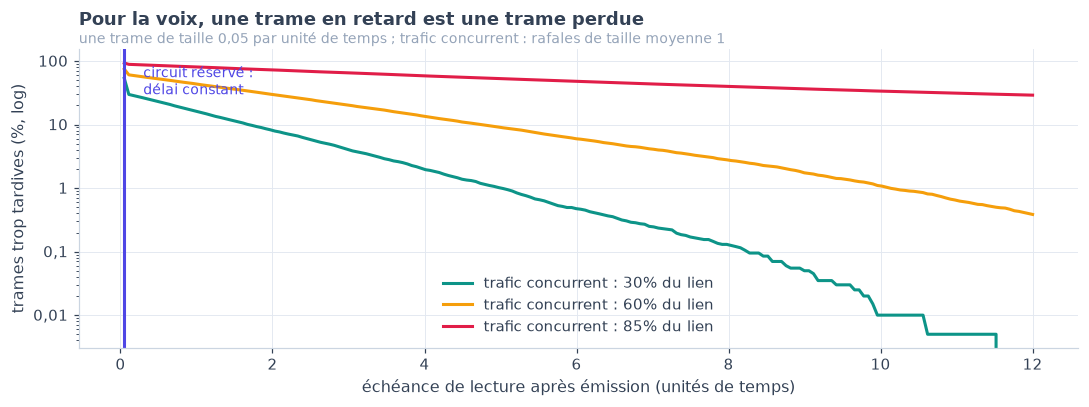

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
D = np.linspace(0.05, 12, 200)
for L, c in [(0.3, TEAL), (0.6, AMBER), (0.85, ROSE)]:
    v = ds.voice_over_packets(L, seed=1)
    ax.plot(D, [(v > dd).mean() * 100 for dd in D], color=c, label=f"trafic concurrent : {L:.0%} du lien")
ax.axvline(0.05, color=INDIGO, lw=2)
ax.text(0.3, 30, "circuit réservé :\ndélai constant", color=INDIGO, fontsize=9)
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("échéance de lecture après émission (unités de temps)"); ax.set_ylabel("trames trop tardives (%, log)")
ax.set_title("Pour la voix, une trame en retard est une trame perdue")
subtitle(ax, "une trame de taille 0,05 par unité de temps ; trafic concurrent : rafales de taille moyenne 1")
ax.legend()
plt.tight_layout(); plt.show()

Plus le lien est chargé par d'autres, plus il faut retarder la lecture pour que les
trames arrivent à temps (le « tampon de gigue » des logiciels de visioconférence) ; une
retransmission arriverait de toute façon trop tard. Sur un circuit téléphonique réservé
(section 4), le délai serait constant.

> **À retenir.** La variabilité des délais réseau vient surtout des **files d'attente**
> (commutateurs, système d'exploitation, hyperviseur, contrôle de congestion de TCP). Elle
> explose près de la saturation, et les pertes de congestion se transforment en délais
> de retransmission de plusieurs centaines de millisecondes.

## 3. Des délais adaptatifs (section *Timeouts and Unbounded Delays*)

Dans un cloud public ou un centre de données mutualisé, les liens, les commutateurs,
les cartes réseau et même les processeurs sont **partagés** entre clients. Un traitement
massif peut saturer un lien ; comme on n'a aucune visibilité sur l'usage des autres, les
délais peuvent varier fortement à cause d'un **voisin bruyant** (noisy neighbor). Le
livre en tire deux conseils :

1. choisir les délais **expérimentalement** : mesurer longtemps, sur beaucoup de
   machines, la distribution des allers-retours ;
2. mieux encore, laisser le système **mesurer en continu** les temps de réponse et leur
   variabilité (la gigue), et **ajuster** automatiquement ses délais. C'est ce que fait
   TCP pour ses retransmissions, et ce que fait le détecteur **phi accrual** (utilisé
   par exemple par Akka et Cassandra).

**L'estimateur de TCP** (Jacobson, 1988) suit une moyenne lissée de l'aller-retour et de
son écart absolu moyen, et fixe le délai de retransmission à
$\text{RTO} = \text{SRTT} + 4\,\text{RTTVAR}$. Appliquons-le à une trace où un voisin
bruyant arrive au milieu de la journée.

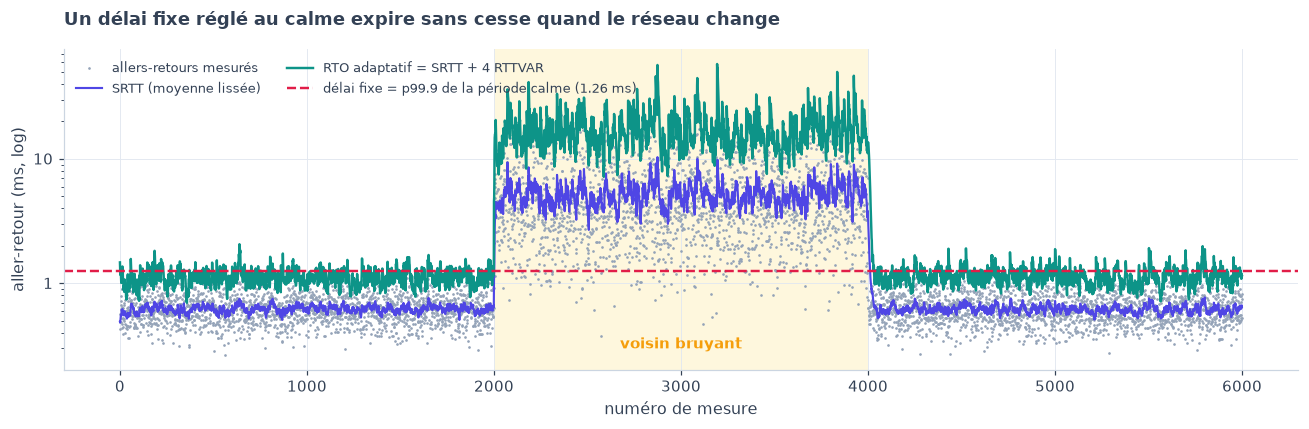

période calme : dépassements du délai fixe   0.2%, du RTO adaptatif   1.7%
période bruit : dépassements du délai fixe  95.0%, du RTO adaptatif   3.8%


In [9]:
n = 6000
calme = ds.rtt_samples(n, seed=5, median_ms=0.6, sigma=0.25, spike_prob=0.0)
bruit = ds.rtt_samples(n, seed=6, median_ms=4.0, sigma=0.7, spike_prob=0.0)
w = np.r_[np.zeros(2000), np.ones(2000), np.zeros(2000)].astype(bool)
trace_rtt = np.where(w, bruit, calme)
est = ds.jacobson_rto(trace_rtt)
fixe = np.percentile(calme[:2000], 99.9)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trace_rtt, ".", ms=1.5, color=GRAY, label="allers-retours mesurés")
ax.plot(est["srtt"], color=INDIGO, lw=1.4, label="SRTT (moyenne lissée)")
ax.plot(est["rto"], color=TEAL, lw=1.6, label="RTO adaptatif = SRTT + 4 RTTVAR")
ax.axhline(fixe, color=ROSE, ls="--", lw=1.6, label=f"délai fixe = p99.9 de la période calme ({fixe:.2f} ms)")
ax.axvspan(2000, 4000, color=LIGHT[AMBER], alpha=0.6, lw=0)
ax.text(3000, 0.3, "voisin bruyant", ha="center", color=AMBER, fontweight="bold")
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("numéro de mesure"); ax.set_ylabel("aller-retour (ms, log)")
ax.set_title("Un délai fixe réglé au calme expire sans cesse quand le réseau change")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()
depasse_rto = trace_rtt[1:] > est["rto"][:-1]          # mesure i comparée au RTO connu avant elle
for nom, m in [("calme", ~w), ("bruit", w)]:
    print(f"période {nom:5s} : dépassements du délai fixe {np.mean(trace_rtt[m] > fixe):6.1%}, "
          f"du RTO adaptatif {np.mean(depasse_rto[m[1:]]):6.1%}")

Le délai fixe, très prudent en période calme, est dépassé par la grande majorité des
mesures pendant l'épisode bruyant (autant de retransmissions inutiles ou de fausses
suspicions) ; le RTO adaptatif suit le réseau en quelques dizaines de mesures et ne
dépasse que quelques pourcents des cas. (Au calme, le RTO, plus serré que le délai fixe,
est un peu plus souvent dépassé : pour TCP, une retransmission inutile coûte peu.)

**Le détecteur phi accrual** (Hayashibara et al., 2004) pousse l'idée plus loin : au lieu
d'un verdict binaire, il calcule un **niveau de suspicion** continu

$$\varphi(t) = -\log_{10} P(\text{le prochain battement arrive encore plus tard que } t),$$

en modélisant les intervalles entre battements par une loi normale estimée sur une
fenêtre glissante. $\varphi = 1$ signifie qu'en déclarant le nœud mort maintenant, on a
une chance sur 10 de se tromper ; $\varphi = 3$, une sur 1 000. Chaque application choisit
son seuil selon le coût d'une erreur. Voici $\varphi$ calculé en continu pour un nœud qui
émet un battement toutes les 100 ms, puis s'arrête à $t = 2{,}05$ s.

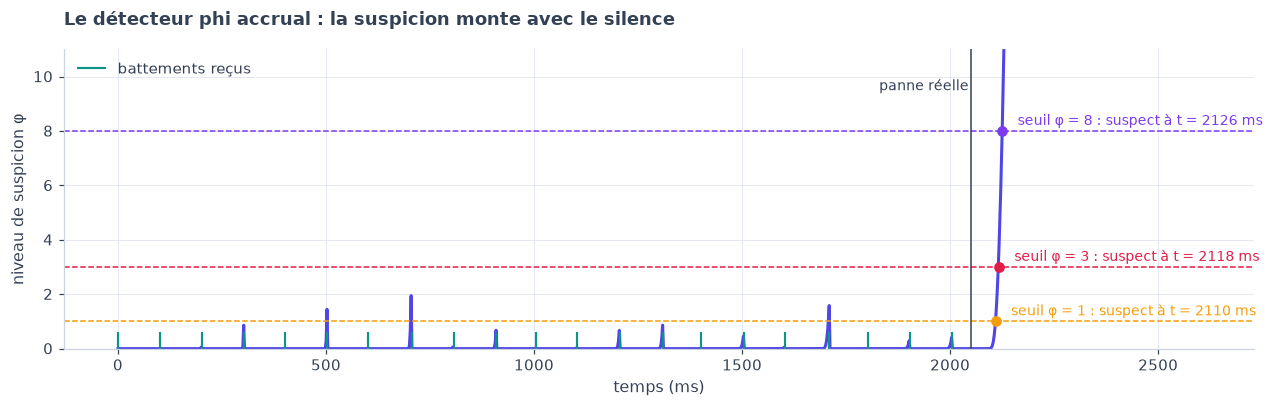

In [10]:
hb_delays = ds.rtt_samples(60, seed=8, median_ms=6.0, sigma=0.8, spike_prob=0.0) / 2
arr = ds.heartbeat_arrivals(21, 100.0, hb_delays)          # 21 battements : t = 0 à 2 000 ms
t_grid = np.linspace(0, 2600, 1300)
phi = ds.phi_trace(arr, t_grid, window=50, min_std=1.0)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(t_grid, phi, color=INDIGO)
ax.vlines(arr, 0, 0.6, color=TEAL, lw=1.4, label="battements reçus")
for th, c in [(1, AMBER), (3, ROSE), (8, VIOLET)]:
    ax.axhline(th, color=c, ls="--", lw=1)
    tc = t_grid[(t_grid > 2050) & (phi > th)][0]
    ax.plot(tc, th, "o", color=c)
    ax.annotate(f"seuil φ = {th} : suspect à t = {tc:.0f} ms", (tc, th), xytext=(10, 4), textcoords="offset points",
                fontsize=9, color=c)
ax.axvline(2050, color=SLATE, lw=1); ax.text(2045, 9.5, "panne réelle", ha="right", fontsize=9, color=SLATE)
ax.set_ylim(0, 11); ax.set_xlabel("temps (ms)"); ax.set_ylabel("niveau de suspicion φ")
ax.set_title("Le détecteur phi accrual : la suspicion monte avec le silence")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Entre deux battements, $\varphi$ remonte un peu puis retombe à zéro à chaque arrivée ;
après la panne, il monte sans cesse, et chaque seuil se traduit par un délai de
détection différent. Comparons enfin trois détecteurs sur le réseau calme puis sur le
voisin bruyant : un délai fixe réglé pour le calme (110 ms), un délai fixe réglé pour le
bruit (150 ms), et phi accrual avec un seuil de 3.

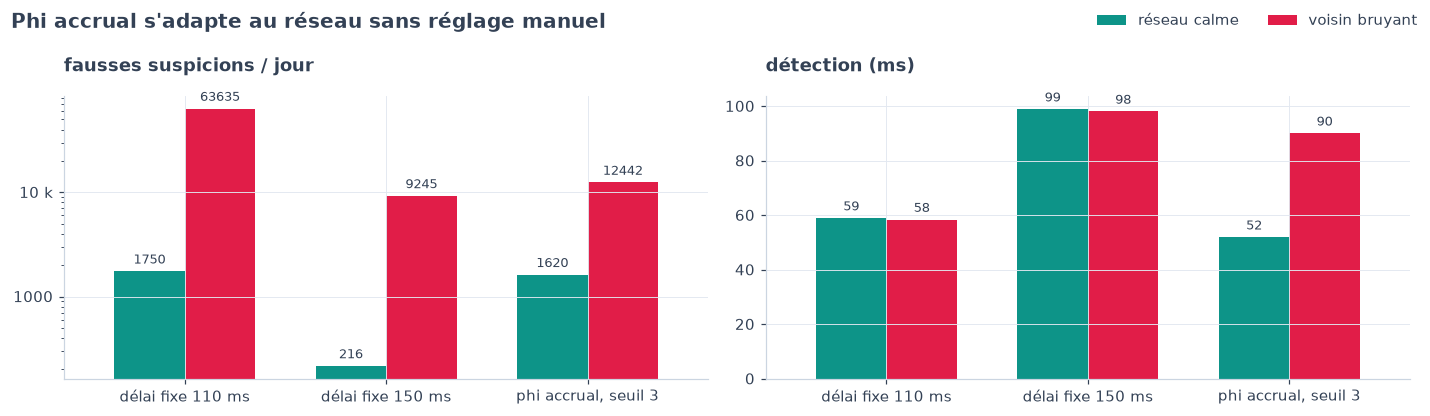

,réseau,détecteur,fausses suspicions / jour,détection (ms)
0,réseau calme,délai fixe 110 ms,1749.6,59.0
1,réseau calme,délai fixe 150 ms,216.0,98.9
2,réseau calme,"phi accrual, seuil 3",1620.0,52.0
3,voisin bruyant,délai fixe 110 ms,63635.2,58.4
4,voisin bruyant,délai fixe 150 ms,9245.0,98.1
5,voisin bruyant,"phi accrual, seuil 3",12441.9,90.1


In [11]:
rows = []
for nom, delays in reseaux.items():
    arr = ds.heartbeat_arrivals(40_000, 100.0, delays)
    for det, f in [("délai fixe 110 ms", lambda a: ds.fixed_timeout_eval(a, 110, 100.0)),
                   ("délai fixe 150 ms", lambda a: ds.fixed_timeout_eval(a, 150, 100.0)),
                   ("phi accrual, seuil 3", lambda a: ds.phi_detector_eval(a, 3, 100.0, window=200, min_std=1.0))]:
        r = f(arr)
        rows.append(dict(réseau=nom, détecteur=det, **{"fausses suspicions / jour": r["faux_positifs"] * 864_000,
                                                      "détection (ms)": r["detection_moy"]}))
C = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, fmt in zip(axes, ["fausses suspicions / jour", "détection (ms)"], ["{:.0f}", "{:.0f}"]):
    piv = C.pivot(index="détecteur", columns="réseau", values=col)[["réseau calme", "voisin bruyant"]]
    piv.plot.bar(ax=ax, color=[TEAL, ROSE], rot=0, width=0.7)
    annotate_bars(ax, fmt, fontsize=8.5)
    ax.set_title(col); ax.set_xlabel(""); ax.get_legend().remove()
    if col.startswith("fausses"):
        ax.set_yscale("log"); plain_log_axis(ax, "y")
plt.suptitle("Phi accrual s'adapte au réseau sans réglage manuel", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
plt.tight_layout(); plt.show()
C.round(1)

Lecture honnête du résultat :

- le délai fixe réglé pour le calme (110 ms) détecte vite partout, mais ses fausses
  suspicions sont multipliées par plus de trente quand le voisin bruyant arrive ;
- le délai fixe réglé pour le bruit (150 ms) est sûr partout, mais lent même quand le
  réseau est calme ;
- phi accrual **détecte vite au calme et ralentit de lui-même dans le bruit** : il
  ajuste son seuil effectif à la variabilité observée. Il ne fait pas de miracle pour
  autant : les rares pics de queue lourde (que la loi normale sous-estime) lui coûtent
  autant qu'aux autres, ce qui explique pourquoi les implémentations réelles ajoutent une
  marge (« pause de battement acceptable »).

> **À retenir.** Les délais réseau varient dans le temps (voisins bruyants, charge) : un
> délai fixe est soit trop court pour les mauvais jours, soit trop long pour les bons.
> Mesurer en continu et adapter (estimateur de TCP, phi accrual) donne un meilleur
> compromis, sans supprimer l'incertitude.

## 4. Réseaux synchrones contre réseaux asynchrones (section *Synchronous Versus Asynchronous Networks*)

Pourquoi ne pas régler le problème au niveau matériel, avec un réseau à délai borné ?
Le **réseau téléphonique fixe** le faisait : un appel établit un **circuit**, une bande
passante fixe réservée sur tout le trajet pendant toute la durée de l'appel. Dans un réseau
RNIS (ISDN), par exemple, les trames passent 4 000 fois par seconde et chaque appel dispose
de 16 bits par trame et par sens : exactement 16 bits toutes les 250 µs, soit
$4\,000 \times 16 = 64$ kbit/s garantis. Comme la place est réservée à chaque saut, il n'y a
**pas de file** : le délai de bout en bout est **borné**. C'est un réseau **synchrone**.

Ethernet et IP, eux, font de la **commutation de paquets** : pas de circuit, des paquets
qui utilisent de façon opportuniste la bande passante disponible, donc des files et des
délais non bornés. Pourquoi ce choix ? Parce que le trafic des centres de données est
fait de **rafales** : une page web, un courriel, un fichier n'ont pas de besoin de débit
particulier, on veut seulement qu'ils passent **le plus vite possible**. Sur un circuit,
il faudrait deviner une bande passante : trop faible, le transfert est inutilement lent ;
trop forte, le circuit ne peut pas être établi. Comparons, pour 10 utilisateurs qui
envoient des fichiers en rafales, un lien découpé en 10 circuits fixes et le même lien
partagé dynamiquement.

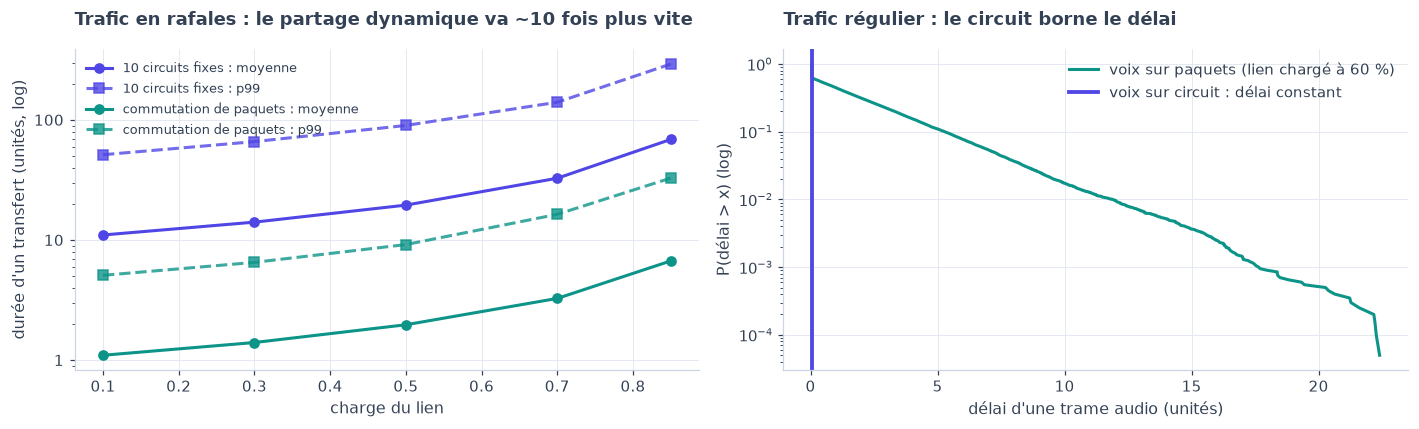

moyenne             p99        
mode   circuit paquets circuit paquets
charge                                
0.10     11.06    1.10   51.50    5.10
0.30     14.15    1.41   66.21    6.54
0.50     19.60    1.98   90.27    9.20
0.70     32.83    3.28  140.88   16.43
0.85     69.11    6.73  293.16   32.95

In [12]:
charges = [0.1, 0.3, 0.5, 0.7, 0.85]
rows = []
for L in charges:
    r = ds.circuit_vs_packet(load=L, seed=2)
    for k in ("circuit", "paquets"):
        rows.append(dict(charge=L, mode=k, moyenne=r[k].mean(), p99=np.percentile(r[k], 99)))
CP = pd.DataFrame(rows)
voix = ds.voice_over_packets(0.6, seed=3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for (k, g), c, lab in zip(CP.groupby("mode"), [INDIGO, TEAL], ["10 circuits fixes", "commutation de paquets"]):
    ax.plot(g.charge, g.moyenne, "o-", color=c, label=f"{lab} : moyenne")
    ax.plot(g.charge, g.p99, "s--", color=c, label=f"{lab} : p99", alpha=0.8)
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("charge du lien"); ax.set_ylabel("durée d'un transfert (unités, log)")
ax.set_title("Trafic en rafales : le partage dynamique va ~10 fois plus vite")
ax.legend(fontsize=8.5)
ax = axes[1]
xs = np.sort(voix)
ax.semilogy(xs, 1 - np.arange(xs.size) / xs.size, color=TEAL, label="voix sur paquets (lien chargé à 60 %)")
ax.axvline(0.05, color=INDIGO, lw=2.5, label="voix sur circuit : délai constant")
ax.set_xlabel("délai d'une trame audio (unités)"); ax.set_ylabel("P(délai > x) (log)")
ax.set_title("Trafic régulier : le circuit borne le délai")
ax.legend()
plt.tight_layout(); plt.show()
CP.pivot(index="charge", columns="mode", values=["moyenne", "p99"]).round(2)

Les deux panneaux résument le compromis. Pour des **rafales** (à gauche), un circuit
fixe n'a que le dixième du lien même quand les neuf autres sont inutilisés : chaque
transfert dure environ dix fois plus longtemps qu'avec le partage dynamique, à toute
charge. Pour un flux **régulier** comme la voix (à droite), le circuit garantit un délai
constant alors que la commutation de paquets impose une queue de distribution.

### Latence et utilisation des ressources (encadré *Latency and Resource Utilization*)

Plus généralement, les délais variables sont la conséquence d'un **partage dynamique**
des ressources. Un câble entre deux centraux qui porte 10 000 appels est découpé
**statiquement** : même seul sur le câble, votre appel n'a qu'un dix-millième de la
capacité. Internet partage **dynamiquement** : les émetteurs se bousculent et les
commutateurs décident paquet par paquet. On y perd la prévisibilité (les files), on y
gagne l'**utilisation** du câble, donc un coût par octet plus faible. Il en va de même
des processeurs (un fil d'exécution attend parfois dans la file de l'ordonnanceur) et des
machines virtuelles de plusieurs clients sur la même machine physique.

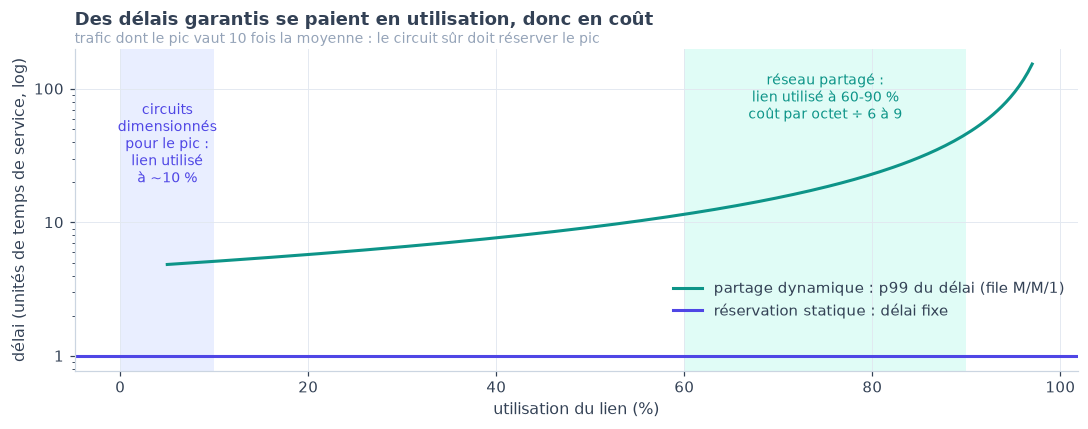

In [13]:
rho = np.linspace(0.05, 0.97, 200)
p99_dyn = -np.log(0.01) / (1 - rho)                  # p99 du temps de séjour M/M/1 (unités de service)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rho * 100, p99_dyn, color=TEAL, label="partage dynamique : p99 du délai (file M/M/1)")
ax.axhline(1, color=INDIGO, lw=2, label="réservation statique : délai fixe")
ax.axvspan(0, 10, color=LIGHT[INDIGO], alpha=0.7, lw=0)
ax.text(5, 20, "circuits\ndimensionnés\npour le pic :\nlien utilisé\nà ~10 %", ha="center", fontsize=9, color=INDIGO)
ax.axvspan(60, 90, color=LIGHT[TEAL], alpha=0.6, lw=0)
ax.text(75, 60, "réseau partagé :\nlien utilisé à 60-90 %\ncoût par octet ÷ 6 à 9", ha="center", fontsize=9, color=TEAL)
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("utilisation du lien (%)"); ax.set_ylabel("délai (unités de temps de service, log)")
ax.set_title("Des délais garantis se paient en utilisation, donc en coût")
subtitle(ax, "trafic dont le pic vaut 10 fois la moyenne : le circuit sûr doit réserver le pic")
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.12))
plt.tight_layout(); plt.show()

Des garanties de latence sont possibles avec des ressources **réservées** (matériel
dédié, bande passante exclusive), mais elles se paient en utilisation, donc en argent.
La mutualisation dynamique est moins chère mais a des délais variables : **ce n'est pas
une loi de la nature, c'est un arbitrage coût/bénéfice**.

**Hybrides.** On a tenté de combiner les deux : ATM (Asynchronous Transfer Mode), concurrent
d'Ethernet dans les années 1980, n'a guère dépassé le cœur des réseaux téléphoniques ;
InfiniBand contrôle le flux de bout en bout au niveau liaison, ce qui réduit les files
sans éliminer les délais de congestion. Avec une **qualité de service** (QoS) soignée
(priorités, ordonnancement des paquets, contrôle d'admission qui limite le débit des
émetteurs), on peut émuler des circuits sur un réseau de paquets, ou borner les délais
statistiquement. Mais ces mécanismes ne sont pas activés dans les centres de données
mutualisés, les clouds publics ou sur Internet : il faut supposer congestion, files et
délais non bornés, et donc déterminer les délais d'expiration **expérimentalement**.

> **À retenir.** Un circuit réservé borne le délai mais gaspille la capacité pour un
> trafic en rafales ; la commutation de paquets maximise l'utilisation au prix de files
> et de délais non bornés. Nos réseaux ont fait ce choix économique : les délais
> d'expiration doivent s'en accommoder.

## Synthèse

- Il n'existe pas de délai d'expiration « correct » : sans borne sur les délais, c'est
  un compromis entre **vitesse de détection** et **fausses suspicions**, et une fausse
  déclaration de décès peut provoquer une cascade.
- La variabilité des délais vient des **files d'attente** ; elle explose près de la
  saturation, et les pertes se changent en retransmissions coûteuses.
- Mieux vaut **mesurer et adapter** les délais (TCP, phi accrual) que les fixer une fois
  pour toutes.
- Les délais non bornés résultent d'un **choix économique** (partage dynamique) : un
  réseau synchrone, à circuits, borne les délais mais gaspille la capacité.

Liens : les files d'attente et les percentiles sont étudiés au chapitre
1 ; le cours 3 montre que les horloges posent des problèmes analogues,
et le cours 4 ce qui arrive quand un nœud déclaré mort ne l'est pas.